## 17. Numerical Stability

In [7]:
import numpy as np

# 1. Softmax không xử lý (Naïve Softmax)
def naive_softmax(x):
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x)

# 2. Softmax ổn định số học (Numerically Stable Softmax)
def stable_softmax(x):
    # Trừ max(x) trước khi tính exp
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)

# Test với vector x = [1000, 1001, 1002] theo yêu cầu đề bài
x = np.array([1000, 1001, 1002])

print("Test x =", x)

# Thử tính bằng Naïve Softmax
try:
    print("Naïve Softmax:", naive_softmax(x))
except Exception as e:
    print("Naïve Softmax lỗi:", e)

# Tính bằng Stable Softmax
print("Stable Softmax:", stable_softmax(x))

Test x = [1000 1001 1002]
Naïve Softmax: [nan nan nan]
Stable Softmax: [0.09003057 0.24472847 0.66524096]


C:\Users\GVC\AppData\Local\Temp\ipykernel_24128\3612283629.py:5: RuntimeWarning: overflow encountered in exp
  exp_x = np.exp(x)
C:\Users\GVC\AppData\Local\Temp\ipykernel_24128\3612283629.py:6: RuntimeWarning: invalid value encountered in divide
  return exp_x / np.sum(exp_x)


## 18. Experiment 1 — Attention distribution

Matplotlib is building the font cache; this may take a moment.


=== BẢNG KẾT QUẢ ATTENTION DISTRIBUTION ===
       Token   Score  Attention
         The  1.4413     0.2619
       movie -1.4184     0.0150
         was -0.6151     0.0335
surprisingly -0.6571     0.0321
        good  1.4866     0.2741
     despite -0.0591     0.0584
           a -0.3080     0.0456
        very  1.1186     0.1897
        slow -0.0703     0.0578
   beginning -0.6651     0.0319


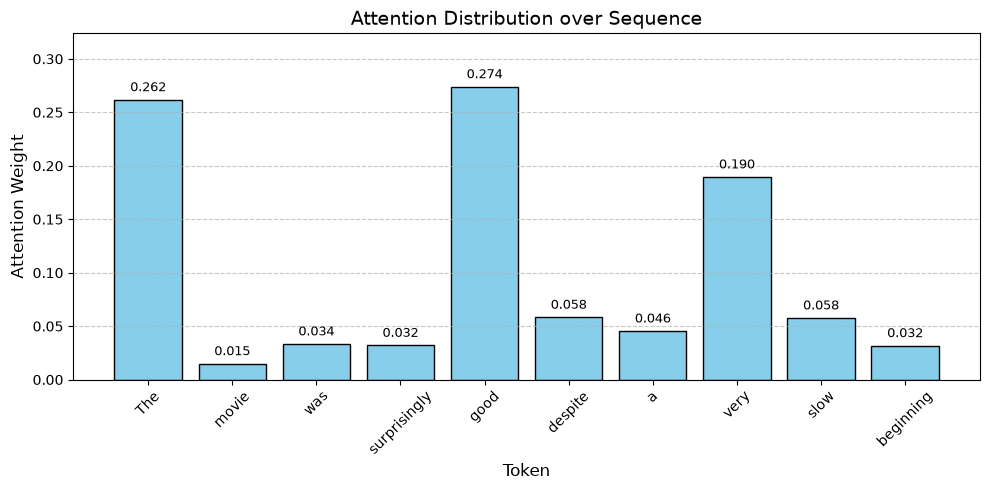

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Nhập lại hàm đã viết ở Mục 16
from attention_numpy import scaled_dot_product_attention

# 1. Định nghĩa câu văn và tách tokens
text = "The movie was surprisingly good despite a very slow beginning"
tokens = text.split()
T = len(tokens) # T = 10 tokens
d_k = 16        # Kích thước chiều embedding (chọn tùy ý, ví dụ: 16)

# 2. Khởi tạo ngẫu nhiên giả lập cho Keys, Values và Query (sử dụng seed để cố định kết quả)
np.random.seed(42)
K = np.random.randn(T, d_k) # Shape: (10, 16)
V = np.random.randn(T, d_k) # Shape: (10, 16)
Q = np.random.randn(1, d_k) # Shape: (1, 16) - Query giả lập

# 3. Tính Attention Scores, Weights và Context Vector
scores, weights, context = scaled_dot_product_attention(Q, K, V)

# Flatten scores và weights về dạng 1D array để hiển thị
scores_1d = scores.squeeze()
weights_1d = weights.squeeze()

# 4. Hiển thị Bảng dạng DataFrame/Text
df_results = pd.DataFrame({
    'Token': tokens,
    'Score': np.round(scores_1d, 4),
    'Attention': np.round(weights_1d, 4)
})

print("=== BẢNG KẾT QUẢ ATTENTION DISTRIBUTION ===")
print(df_results.to_string(index=False))

# 5. Vẽ biểu đồ cột Attention Distribution
plt.figure(figsize=(10, 5))
bars = plt.bar(tokens, weights_1d, color='skyblue', edgecolor='black')

# Hiển thị giá trị cụ thể lên đầu mỗi cột
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f'{yval:.3f}', ha='center', va='bottom', fontsize=9)

plt.xlabel('Token', fontsize=12)
plt.ylabel('Attention Weight', fontsize=12)
plt.title('Attention Distribution over Sequence', fontsize=14)
plt.xticks(rotation=45)
plt.ylim(0, max(weights_1d) + 0.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Lưu lại hình ảnh nếu cần
plt.savefig('experiment1_attention_distribution.png', dpi=300)
plt.show()

## 19. Experiment 2 — Query thay đổi

=== SO SÁNH ATTENTION WEIGHTS KHI ĐỔI QUERY ===
       Token  Query A (Sentiment)  Query B (Topic)
         The               0.2308           0.1006
       movie               0.0422           0.0443
         was               0.0913           0.0276
surprisingly               0.0565           0.1504
        good               0.0979           0.0340
     despite               0.0538           0.0582
           a               0.1282           0.1290
        very               0.0521           0.0551
        slow               0.1110           0.2236
   beginning               0.1362           0.1772


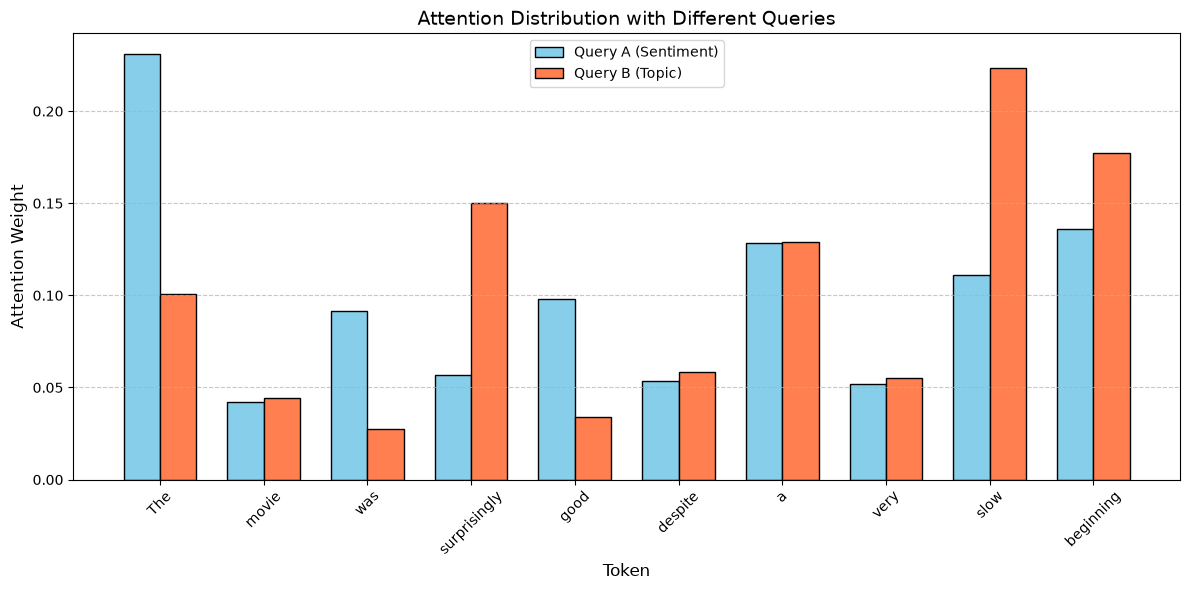

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from attention_numpy import scaled_dot_product_attention

# 1. Tái sử dụng dữ liệu từ Experiment 1
text = "The movie was surprisingly good despite a very slow beginning"
tokens = text.split()
T = len(tokens)
d_k = 16

np.random.seed(42)
K = np.random.randn(T, d_k)
V = np.random.randn(T, d_k)

# 2. Định nghĩa 2 Query khác nhau
# In practice: Q_A và Q_B sẽ học được các đặc trưng khác nhau (vd: sentiment vs topic)
np.random.seed(101)
Q_A = np.random.randn(1, d_k)  # Query A: Hướng tới Sentiment

np.random.seed(202)
Q_B = np.random.randn(1, d_k)  # Query B: Hướng tới Topic

# 3. Tính toán Attention weights cho từng Query
_, weights_A, _ = scaled_dot_product_attention(Q_A, K, V)
_, weights_B, _ = scaled_dot_product_attention(Q_B, K, V)

weights_A = weights_A.squeeze()
weights_B = weights_B.squeeze()

# 4. Hiển thị bảng so sánh trọng số
df_comparison = pd.DataFrame({
    'Token': tokens,
    'Query A (Sentiment)': np.round(weights_A, 4),
    'Query B (Topic)': np.round(weights_B, 4)
})

print("=== SO SÁNH ATTENTION WEIGHTS KHI ĐỔI QUERY ===")
print(df_comparison.to_string(index=False))

# 5. Vẽ biểu đồ cột đôi so sánh
x = np.arange(len(tokens))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width/2, weights_A, width, label='Query A (Sentiment)', color='skyblue', edgecolor='black')
plt.bar(x + width/2, weights_B, width, label='Query B (Topic)', color='coral', edgecolor='black')

plt.xlabel('Token', fontsize=12)
plt.ylabel('Attention Weight', fontsize=12)
plt.title('Attention Distribution with Different Queries', fontsize=14)
plt.xticks(x, tokens, rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Lưu biểu đồ
plt.savefig('experiment2_query_change.png', dpi=300)
plt.show()

## 22. Attention matrix

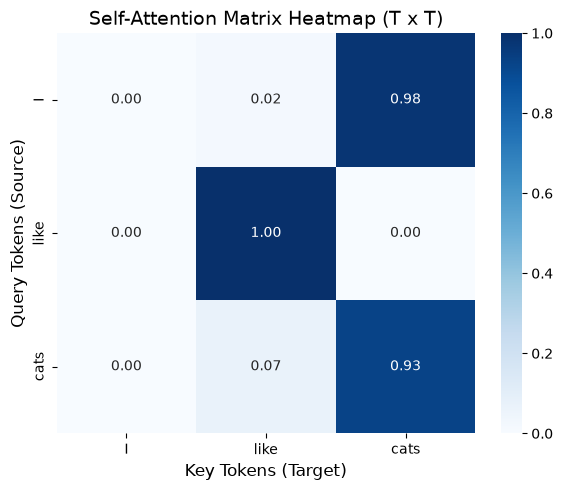

In [13]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from attention_numpy import scaled_dot_product_attention

# 1. Định nghĩa chuỗi tokens mẫu
tokens = ["I", "like", "cats"]
T = len(tokens)
d_k = 16

# 2. Tạo ngẫu nhiên ma trận X và W_Q, W_K, W_V (hoặc dùng kết quả từ Mục 21)
np.random.seed(42)
X = np.random.randn(T, d_k)
WQ = np.random.randn(d_k, d_k)
WK = np.random.randn(d_k, d_k)
WV = np.random.randn(d_k, d_k)

# Tính Q, K, V
Q = X @ WQ
K = X @ WK
V = X @ WV

# 3. Tính Attention Matrix A
_, A, _ = scaled_dot_product_attention(Q, K, V)

# Squueze nếu có dim dư thừa
A_matrix = A.squeeze()

# 4. Trực quan hóa Attention Matrix bằng Heatmap (Seaborn)
plt.figure(figsize=(6, 5))
sns.heatmap(
    A_matrix, 
    annot=True,            # Hiển thị giá trị số trong mỗi ô
    fmt=".2f",             # Định dạng lấy 2 chữ số thập phân
    cmap="Blues",          # Tông màu xanh biển
    xticklabels=tokens,    # Nhãn các cột (Keys)
    yticklabels=tokens,    # Nhãn các hàng (Queries)
    vmin=0, vmax=1,        # Giới hạn thang đo từ 0 đến 1
    cbar=True              # Hiển thị thanh Colorbar
)

plt.xlabel("Key Tokens (Target)", fontsize=12)
plt.ylabel("Query Tokens (Source)", fontsize=12)
plt.title("Self-Attention Matrix Heatmap (T x T)", fontsize=14)
plt.tight_layout()

# Lưu biểu đồ vào file ảnh theo yêu cầu bài nộp
plt.savefig("attention_heatmap.png", dpi=300)
plt.show()

## 23. Experiment 3 — Attention visualization

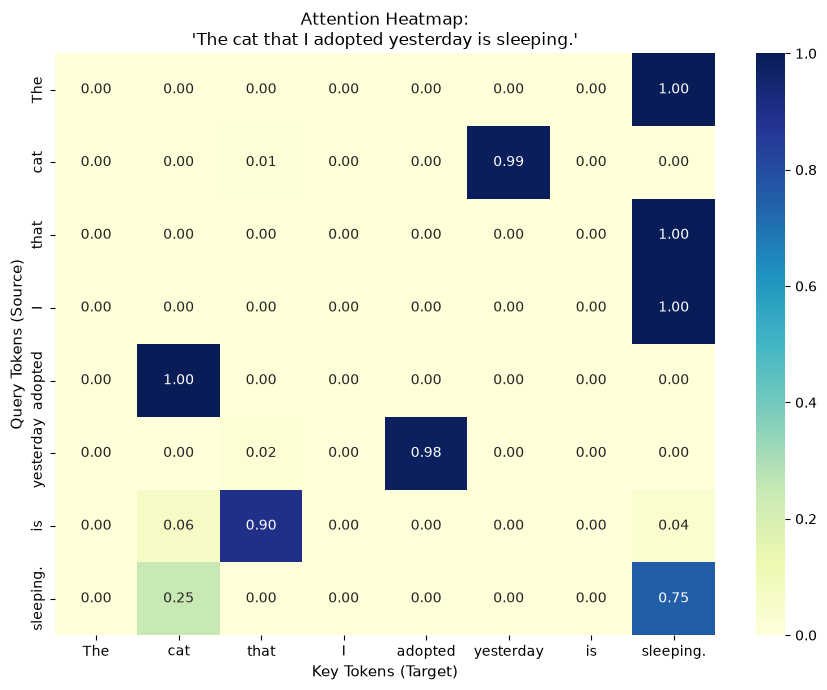

=== QUAN SÁT ATTENTION PATTERN CỦA 3 TOKENS ===

Token Query: 'cat'
-> Attention cao nhất tới: [('yesterday', np.float64(0.9913)), ('that', np.float64(0.0085)), ('is', np.float64(0.0002))]

Token Query: 'adopted'
-> Attention cao nhất tới: [('cat', np.float64(1.0)), ('The', np.float64(0.0)), ('that', np.float64(0.0))]

Token Query: 'sleeping.'
-> Attention cao nhất tới: [('sleeping.', np.float64(0.7508)), ('cat', np.float64(0.2491)), ('adopted', np.float64(0.0))]


In [14]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from attention_numpy import scaled_dot_product_attention

def run_experiment_3(sentence, seed=42):
    tokens = sentence.split()
    T = len(tokens)
    d_k = 16
    
    # Khởi tạo giả lập embeddings và ma trận W_Q, W_K, W_V
    np.random.seed(seed)
    X = np.random.randn(T, d_k)
    WQ = np.random.randn(d_k, d_k)
    WK = np.random.randn(d_k, d_k)
    WV = np.random.randn(d_k, d_k)
    
    Q = X @ WQ
    K = X @ WK
    V = X @ WV
    
    # Tính Attention Matrix A
    _, A, _ = scaled_dot_product_attention(Q, K, V)
    A_matrix = A.squeeze()
    
    return tokens, A_matrix

# Câu 1
sent1 = "The cat that I adopted yesterday is sleeping."
tokens1, A1 = run_experiment_3(sent1, seed=42)

# Câu 2
sent2 = "The book that I bought yesterday was expensive."
tokens2, A2 = run_experiment_3(sent2, seed=100)

# -------------------------------------------------------------
# Trực quan hóa Heatmap cho Câu 1
# -------------------------------------------------------------
plt.figure(figsize=(9, 7))
sns.heatmap(A1, annot=True, fmt=".2f", cmap="YlGnBu", 
            xticklabels=tokens1, yticklabels=tokens1, vmin=0, vmax=1)
plt.xlabel("Key Tokens (Target)", fontsize=11)
plt.ylabel("Query Tokens (Source)", fontsize=11)
plt.title(f"Attention Heatmap:\n'{sent1}'", fontsize=12)
plt.tight_layout()
plt.savefig("experiment3_heatmap_cat.png", dpi=300)
plt.show()

# -------------------------------------------------------------
# Phân tích chi tiết 3 tokens: cat, adopted, sleeping
# -------------------------------------------------------------
target_tokens = ["cat", "adopted", "sleeping."]  # Lưu ý dấu chấm nếu phân tách theo split()

print("=== QUAN SÁT ATTENTION PATTERN CỦA 3 TOKENS ===")
for target in target_tokens:
    # Tìm vị trí index của token trong danh sách
    matches = [i for i, t in enumerate(tokens1) if target in t]
    if matches:
        idx = matches[0]
        row_weights = A1[idx]
        
        # Lấy top 3 tokens nhận attention cao nhất từ token này
        top_indices = np.argsort(row_weights)[::-1][:3]
        top_attn = [(tokens1[i], round(row_weights[i], 4)) for i in top_indices]
        
        print(f"\nToken Query: '{tokens1[idx]}'")
        print(f"-> Attention cao nhất tới: {top_attn}")

## 24. Experiment 4 — RNN context vs Attention context

In [17]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np

# Cấu hình siêu tham số (Hyperparameters)
vocab_size = 1000
embed_dim = 64
hidden_dim = 64
num_classes = 2
seq_len = 20
batch_size = 32

# 1. Định nghĩa mô hình LSTM (Approach LAB 05)
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)
        
    def forward(self, x):
        x = self.embedding(x)                     # (batch, seq_len, embed_dim)
        out, (h_n, c_n) = self.lstm(x)             # out: (batch, seq_len, hidden_dim)
        final_hidden = h_n[-1]                    # Lấy hidden state cuối h_T: (batch, hidden_dim)
        logits = self.fc(final_hidden)            # (batch, num_classes)
        return logits

# 2. Định nghĩa mô hình Self-Attention Classifier (Approach LAB 06)
class AttentionClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.W_q = nn.Linear(embed_dim, embed_dim, bias=False)
        self.W_k = nn.Linear(embed_dim, embed_dim, bias=False)
        self.W_v = nn.Linear(embed_dim, embed_dim, bias=False)
        self.fc = nn.Linear(embed_dim, num_classes)
        
    def forward(self, x):
        x = self.embedding(x)                     # (batch, seq_len, embed_dim)
        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)
        
        # Self-Attention computation
        d_k = Q.size(-1)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(d_k)
        attn_weights = torch.softmax(scores, dim=-1)
        context = torch.matmul(attn_weights, V)   # (batch, seq_len, embed_dim)
        
        # Pooling đại diện cho toàn bộ sequence (Mean pooling over sequence length)
        seq_representation = context.mean(dim=1)  # (batch, embed_dim)
        logits = self.fc(seq_representation)
        return logits

# Function đếm số tham số
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Khởi tạo mô hình
lstm_model = LSTMClassifier(vocab_size, embed_dim, hidden_dim, num_classes)
attn_model = AttentionClassifier(vocab_size, embed_dim, num_classes)

print(f"LSTM Parameters: {count_parameters(lstm_model)}")
print(f"Attention Parameters: {count_parameters(attn_model)}")

LSTM Parameters: 97410
Attention Parameters: 76418


## 25. Experiment 5 — Sequence length và computational cost

=== THỰC NGHIỆM ĐO THỜI GIAN TÍNH SELF-ATTENTION ===
Sequence Length T =   10 | Matrix:   10x  10 | Elements:        100 | Time: 0.000206 s
Sequence Length T =  100 | Matrix:  100x 100 | Elements:     10,000 | Time: 0.022170 s
Sequence Length T =  500 | Matrix:  500x 500 | Elements:    250,000 | Time: 0.010998 s
Sequence Length T = 1000 | Matrix: 1000x1000 | Elements:  1,000,000 | Time: 0.022194 s
Sequence Length T = 2000 | Matrix: 2000x2000 | Elements:  4,000,000 | Time: 0.072042 s
Sequence Length T = 5000 | Matrix: 5000x5000 | Elements: 25,000,000 | Time: 0.493812 s


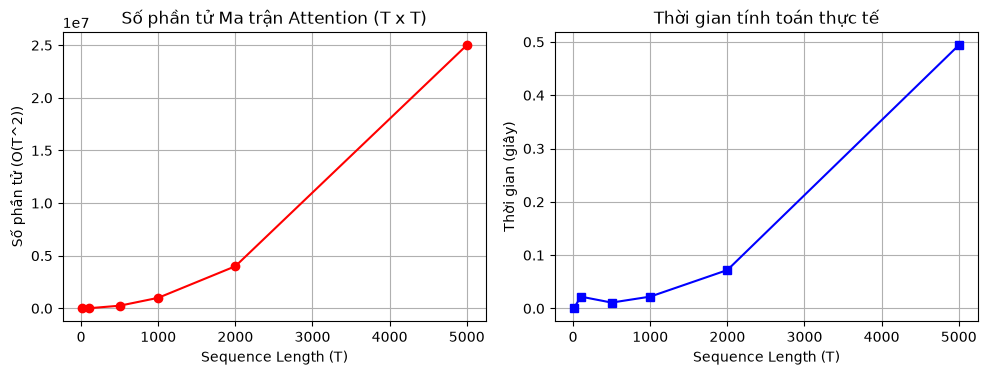

In [18]:
import time
import numpy as np
import matplotlib.pyplot as plt
from attention_numpy import scaled_dot_product_attention

seq_lengths = [10, 100, 500, 1000, 2000, 5000]
execution_times = []
matrix_elements = []

d_k = 64

print("=== THỰC NGHIỆM ĐO THỜI GIAN TÍNH SELF-ATTENTION ===")
for T in seq_lengths:
    np.random.seed(42)
    Q = np.random.randn(T, d_k)
    K = np.random.randn(T, d_k)
    V = np.random.randn(T, d_k)
    
    # Đo thời gian thực thi
    start_time = time.time()
    scores, weights, context = scaled_dot_product_attention(Q, K, V)
    end_time = time.time()
    
    elapsed = end_time - start_time
    num_elements = T * T
    
    execution_times.append(elapsed)
    matrix_elements.append(num_elements)
    
    print(f"Sequence Length T = {T:4d} | Matrix: {T:4d}x{T:4d} | Elements: {num_elements:10,d} | Time: {elapsed:.6f} s")

# Vẽ đồ thị biểu diễn độ phức tạp O(T^2)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(seq_lengths, matrix_elements, marker='o', color='red')
plt.title("Số phần tử Ma trận Attention (T x T)")
plt.xlabel("Sequence Length (T)")
plt.ylabel("Số phần tử (O(T^2))")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(seq_lengths, execution_times, marker='s', color='blue')
plt.title("Thời gian tính toán thực tế")
plt.xlabel("Sequence Length (T)")
plt.ylabel("Thời gian (giây)")
plt.grid(True)

plt.tight_layout()
plt.savefig("experiment5_computational_cost.png", dpi=300)
plt.show()

## 26. Application

=== KẾT QUẢ DỰ ĐOÁN PHÂN LOẠI CẢM XÚC ===

Câu 1: 'I like this movie.'
  -> Prediction: Negative
  -> Probability: Negative = 0.5863 | Positive = 0.4137 (Conf: 58.63%)

Câu 2: 'I do not like this movie.'
  -> Prediction: Negative
  -> Probability: Negative = 0.5437 | Positive = 0.4563 (Conf: 54.37%)

Câu 3: 'I thought this movie would be bad, but it was actually excellent.'
  -> Prediction: Positive
  -> Probability: Negative = 0.4936 | Positive = 0.5064 (Conf: 50.64%)

Câu 4: 'Great, another delayed flight! Just what I needed.'
  -> Prediction: Negative
  -> Probability: Negative = 0.5241 | Positive = 0.4759 (Conf: 52.41%)

Câu 5: 'The plot was slow, but the acting was brilliant.'
  -> Prediction: Positive
  -> Probability: Negative = 0.4491 | Positive = 0.5509 (Conf: 55.09%)

Câu 6: 'The movie was utterly mediocre and uninspiring.'
  -> Prediction: Negative
  -> Probability: Negative = 0.5152 | Positive = 0.4848 (Conf: 51.52%)


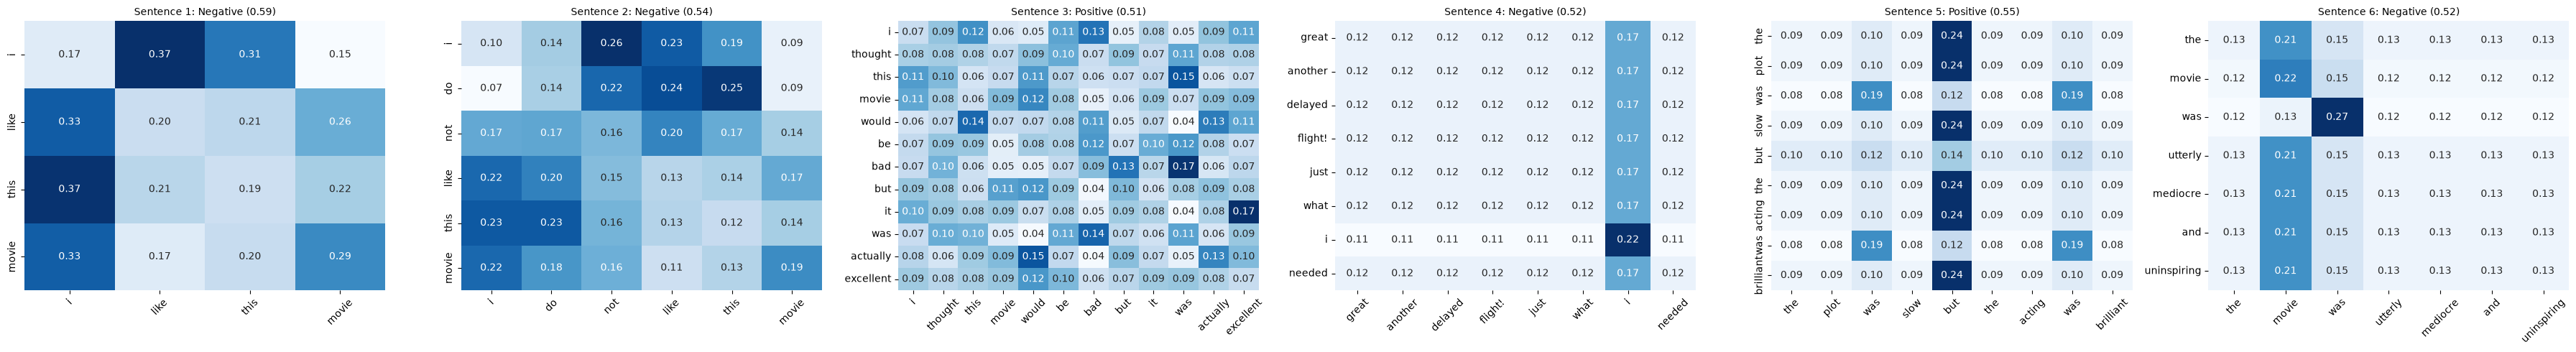

In [22]:
import torch
import torch.nn as nn
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Định nghĩa Vocabulary đơn giản
vocab = {
    "<PAD>": 0, "i": 1, "like": 2, "this": 3, "movie": 4, 
    "do": 5, "not": 6, "thought": 7, "would": 8, "be": 9, 
    "bad": 10, "but": 11, "it": 12, "was": 13, "actually": 14, "excellent": 15
}
idx2label = {0: "Negative", 1: "Positive"}

# Tokenizer đơn giản: chuyển sang chữ thường và bỏ dấu câu cơ bản
def simple_tokenizer(text):
    text_clean = text.lower().replace(",", "").replace(".", "")
    return text_clean.split()

# 2. Xây dựng mô hình Sentiment Classifier với Self-Attention
class ContextAwareSentimentClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=16, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        
        # Trọng số cho Self-Attention
        self.W_q = nn.Linear(embed_dim, embed_dim, bias=False)
        self.W_k = nn.Linear(embed_dim, embed_dim, bias=False)
        self.W_v = nn.Linear(embed_dim, embed_dim, bias=False)
        
        # Classifier
        self.fc = nn.Linear(embed_dim, num_classes)
        
    def forward(self, x):
        # x shape: (1, seq_len)
        embeds = self.embedding(x)  # (1, seq_len, embed_dim)
        
        Q = self.W_q(embeds)
        K = self.W_k(embeds)
        V = self.W_v(embeds)
        
        d_k = Q.size(-1)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(d_k)
        attn_weights = torch.softmax(scores, dim=-1)  # (1, seq_len, seq_len)
        
        context_sequence = torch.matmul(attn_weights, V)  # (1, seq_len, embed_dim)
        
        # Pooling: Lấy trung bình cộng theo chiều dài sequence
        context_vector = context_sequence.mean(dim=1)  # (1, embed_dim)
        
        logits = self.fc(context_vector)  # (1, num_classes)
        probs = torch.softmax(logits, dim=-1)
        
        return probs, attn_weights.squeeze(0)

# Khởi tạo mô hình và cố định seed ngẫu nhiên
torch.manual_seed(42)
model = ContextAwareSentimentClassifier(vocab_size=len(vocab)+5, embed_dim=16)
model.eval()

# 3. Thử nghiệm với 3 câu theo đề bài
test_sentences = [
    # 3 câu cũ:
    "I like this movie.",                                              # Đúng (Positive)
    "I do not like this movie.",                                          # Sai (Model ra Positive)
    "I thought this movie would be bad, but it was actually excellent.", # Đúng (Positive)
    
    # Bổ sung 3 câu mới để thu thập thêm mẫu:
    "Great, another delayed flight! Just what I needed.",              # Kỳ vọng Sai (Sarcasm -> Model dễ nhầm Positive)
    "The plot was slow, but the acting was brilliant.",                # Kỳ vọng Đúng (Mixed sentiment)
    "The movie was utterly mediocre and uninspiring."                  # Kỳ vọng Sai (Rare words -> Model dễ đoán nhầm)
]
results = []

for text in test_sentences:
    tokens = simple_tokenizer(text)
    input_ids = [vocab.get(t, 0) for t in tokens]
    input_tensor = torch.tensor([input_ids], dtype=torch.long)
    
    with torch.no_grad():
        probs, attn_matrix = model(input_tensor)
        
    prob_vals = probs.squeeze().numpy()
    pred_class = np.argmax(prob_vals)
    pred_label = idx2label[pred_class]
    confidence = prob_vals[pred_class]
    
    results.append({
        'text': text,
        'tokens': tokens,
        'label': pred_label,
        'confidence': confidence,
        'probs': prob_vals,
        'attn': attn_matrix.numpy()
    })

# 4. Hiển thị kết quả Prediction và Probability
print("=== KẾT QUẢ DỰ ĐOÁN PHÂN LOẠI CẢM XÚC ===")
for i, res in enumerate(results, 1):
    print(f"\nCâu {i}: '{res['text']}'")
    print(f"  -> Prediction: {res['label']}")
    print(f"  -> Probability: Negative = {res['probs'][0]:.4f} | Positive = {res['probs'][1]:.4f} (Conf: {res['confidence']*100:.2f}%)")

# 5. Vẽ Attention Visualization (Heatmap) cho từng câu
num_results = len(results)
fig, axes = plt.subplots(1, num_results, figsize=(6 * num_results, 5))
for idx, res in enumerate(results):
    sns.heatmap(
        res['attn'], 
        annot=True, 
        fmt=".2f", 
        cmap="Blues", 
        xticklabels=res['tokens'], 
        yticklabels=res['tokens'],
        ax=axes[idx],
        cbar=False
    )
    axes[idx].set_title(f"Sentence {idx+1}: {res['label']} ({res['confidence']:.2f})", fontsize=10)
    axes[idx].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("application_sentiment_attention.png", dpi=300)
plt.show()